### Workspace for Matt

## Data load, clean and match

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

# Locate data directory (relative to notebook: 'data/', with fallback to '../Data_Raw/')
data_dir = Path('data') if Path('data').exists() else Path('../Data_Raw')
if not data_dir.exists():
    data_dir = Path('Data_Raw')

# Load raw CSV datasets into DataFrames (using first-row headers as column names)
Harris1 = pd.read_csv(data_dir / 'HarrisPartI.csv', na_values=['NA', 'XXXX', 'NONE'])
Harris3 = pd.read_csv(data_dir / 'HarrisPartIII.csv', na_values=['NA', 'XXXX', 'NONE'])
vandenBerg = pd.read_csv(data_dir / 'vandenBerg_table2.csv', na_values=['NA', 'XXXX', 'NONE'])
Krause = pd.read_csv(data_dir / 'Krause21.csv', na_values=['NA', 'XXXX', 'NONE'])

# Strip leading '#' from '#NGC' so vandenBerg.NGC works as a direct attribute
vandenBerg.columns = [col.lstrip('#') for col in vandenBerg.columns]

# Lowercase aliases for convenience
harris1, harris3, vandenberg, krause = Harris1, Harris3, vandenBerg, Krause

# Verify access format: Harris1.ID[4]
print(f"Harris1.ID[4] = '{Harris1.ID[3]}'")
print(f"Loaded shapes: Harris1 {Harris1.shape}, Harris3 {Harris3.shape}, vandenBerg {vandenBerg.shape}, Krause {Krause.shape}")


Harris1.ID[4] = 'Whiting 1'
Loaded shapes: Harris1 (157, 11), Harris3 (157, 13), vandenBerg (55, 13), Krause (61, 8)


In [ ]:
"""Run after loading Harris1, Harris3, vandenBerg and Krause.

Creates master and match_report.
"""
import re
from collections import defaultdict

# Abreviation dictionary
NAME_MAP = {
    'RUPRECHT106': 'RUP106',
    'PALOMAR12': 'PAL12',
    'TER8': 'TERZAN8',
}

# normalise name if not na, conform to upper case, check for null identifier. Check dictionary to see for abreviation. returns correct case condition, null identifier or abbreviation
def normalise_name(value):
    if pd.isna(value):
        return None
    key = re.sub(r'\s+', '', str(value)).upper()
    if key in {'', 'NA', 'NAN', 'NONE', 'XXXX'}:
        return None
    return NAME_MAP.get(key, key)

# matches ngc ID
def ngc_number(value, bare_number=False):
    key = normalise_name(value)
    if key is None:
        return pd.NA
    pattern = r'(\d+)(?:\.0+)?' if bare_number else r'NGC(\d+)'
    found = re.fullmatch(pattern, key)
    return int(found.group(1)) if found else pd.NA

# Work on copies; protect original csv files.
sources = {
    'h1': Harris1.copy(),
    'h3': Harris3.copy(),
    'k': Krause.copy(),
    'vb': vandenBerg.copy(),
}
sources['vb'] = sources['vb'].rename(columns={'#NGC': 'NGC'})
primary_column = {'h1': 'ID', 'h3': 'ID', 'k': 'Object', 'vb': 'NGC'}
alias_column = {'h1': 'Name', 'h3': None, 'k': 'AltName', 'vb': 'Name'}

for source, frame in sources.items():
    if not frame.columns.is_unique:
        raise ValueError(f'{source}: duplicate column names need review.')
    original = frame[primary_column[source]]
    numbers = original.map(lambda x: ngc_number(x, bare_number=(source == 'vb')))
    # In vb this converts its existing NGC field to nullable integers.
    # Other sources gain a derived NGC fieldretain original IDs.
    frame['NGC'] = pd.array(numbers, dtype='Int64')

# Build a lookup using Harris primary IDs AND its listed alternative names.
harris_lookup = defaultdict(set)
display_names = {}
for _, row in sources['h1'].iterrows():
    if normalise_name(row['ID']) is None:
        raise ValueError('Harris I contains a missing primary ID.')
    cluster_id = str(row['ID']).strip()
    if cluster_id in display_names:
        raise ValueError(f'Duplicate Harris I ID: {cluster_id}')
    display_names[cluster_id] = (
        str(row['Name']).strip() if normalise_name(row['Name']) else cluster_id
    )
    for value in [row['ID'], row['Name']]:
        key = normalise_name(value)
        if key is not None:
            harris_lookup[key].add(cluster_id)

def lookup_unique(key):
    candidates = harris_lookup.get(key, set())
    if len(candidates) > 1:
        raise ValueError(f'Ambiguous Harris name {key!r}: {sorted(candidates)}')
    return next(iter(candidates)) if candidates else None

records = []
indexed_sources = {}
for source, frame in sources.items():
    common_ids = []
    for row_position, (_, row) in enumerate(frame.iterrows()):
        number = row['NGC']
        primary = row[primary_column[source]]
        alias = row[alias_column[source]] if alias_column[source] else pd.NA
        primary_key = (
            f'NGC{number}' if pd.notna(number) else
            normalise_name(alias if source == 'vb' else primary)
        )
        alias_key = normalise_name(alias)
        primary_match = lookup_unique(primary_key)
        alias_match = lookup_unique(alias_key)

        if primary_match and alias_match and primary_match != alias_match:
            raise ValueError(f'{source} row {row_position}: ID and alias disagree.')
        if pd.notna(number) and alias_match:
            if normalise_name(alias_match) != f'NGC{number}':
                raise ValueError(f'{source} row {row_position}: NGC number conflicts with alias.')

        cluster_id = primary_match or alias_match
        if cluster_id:
            method = 'NGC' if pd.notna(number) and primary_match else (
                'primary name' if primary_match else 'Harris alias'
            )
        else:
            # Source-qualified keys to avoid accidentally merging unresolved objects.
            label = primary_key or alias_key or f'ROW{row_position}'
            cluster_id = f'UNMATCHED:{source}:{label}'
            method = 'unmatched - review'
            display_names[cluster_id] = (
                str(alias).strip() if normalise_name(alias) else
                str(primary).strip() if normalise_name(primary) else cluster_id
            )

        common_ids.append(cluster_id)
        records.append({
            'source': source, 'source_row': row_position,
            'original_id': primary, 'original_alias': alias,
            'cluster_id': cluster_id, 'NGC': number, 'match_method': method,
        })

    if pd.Index(common_ids).has_duplicates:
        repeated = pd.Series(common_ids)[pd.Series(common_ids).duplicated(keep=False)]
        raise ValueError(f'{source}: multiple rows map to one object; review {repeated.tolist()}')
    frame.index = pd.Index(common_ids, name='cluster_id')
    indexed_sources[source] = frame

# Outer alignment keeps every source row
master = pd.concat(indexed_sources, axis=1, join='outer', sort=False)
master.columns.names = ['source', 'quantity']

match_report = pd.DataFrame(records)
match_report['NGC'] = pd.array(match_report['NGC'], dtype='Int64')
meta = pd.DataFrame(index=master.index)
meta['cluster_id'] = master.index.astype('string')
meta['preferred_name'] = pd.Series(display_names, dtype='string').reindex(master.index)
meta['NGC'] = pd.Series(pd.NA, index=master.index, dtype='Int64')
for frame in indexed_sources.values():
    meta['NGC'] = meta['NGC'].fillna(frame['NGC'].reindex(master.index))
meta['matched_to_harris'] = master.index.isin(sources['h1']['ID'].str.strip())
meta.columns = pd.MultiIndex.from_product([['meta'], meta.columns], names=['source', 'quantity'])
master = pd.concat([meta, master], axis=1)

print(f'Master table: {len(master)} clusters, {master.shape[1]} columns')
print('\nMatching summary:')
print(pd.crosstab(match_report['source'], match_report['match_method']).to_string())
unmatched = match_report[match_report['match_method'] == 'unmatched - review']
print('\nUnmatched rows (retained in master):')
print(unmatched[['source', 'original_id', 'original_alias', 'cluster_id']].to_string(index=False))

# Notebook access examples:
# master['h1']                         # All Harris I columns
# master['h3']['v_r']                   # Radial velocities
# master.loc['NGC 104', ('vb', 'Age')]   # One cluster and measurement
# master['meta']['NGC']                 # Nullable integer NGC numbers
# master[[('vb', 'Age'), ('vb', 'FeH')]].dropna()  # Plot-specific sample


Master table: 158 clusters, 52 columns

Matching summary:
match_method  NGC  primary name  unmatched - review
source                                             
h1            104            53                   0
h3            104            53                   0
k              58             3                   0
vb             52             2                   1

Unmatched rows (retained in master):
source original_id original_alias         cluster_id
    vb        <NA>          Arp21 UNMATCHED:vb:ARP21


In [3]:
# save master csv
master.to_csv(data_dir / "master_catalogue.csv", index=True)
""" example on how to load csv
master = pd.read_csv(
    data_dir / "master_catalogue.csv",
    header=[0, 1],
    index_col=0
)

# Restore nullable integer types for NGC numbers
for source in ["meta", "h1", "h3", "k", "vb"]:
    master[(source, "NGC")] = master[(source, "NGC")].astype("Int64")

"""

' example on how to load csv\nmaster = pd.read_csv(\n    data_dir / "master_catalogue.csv",\n    header=[0, 1],\n    index_col=0\n)\n\n# Restore nullable integer types for NGC numbers\nfor source in ["meta", "h1", "h3", "k", "vb"]:\n    master[(source, "NGC")] = master[(source, "NGC")].astype("Int64")\n\n'

### Data cleaning
Filter out maximally informative data points for analysis, if includes age + Fe/H + R_gc + v_LSR data. Prioritises VandenBerg Data since it includes error and uses better method.

In [11]:
from pathlib import Path
import pandas as pd

# Locate data directory (relative to notebook)
for p in [Path('data'), Path('PHYS3116_Larawag/data'), Path('../data')]:
    if (p / 'master_catalogue.csv').exists():
        data_dir = p
        break

# Read master catalogue
master_raw = pd.read_csv(data_dir / 'master_catalogue.csv', header=[0, 1], index_col=0, dtype=str, encoding='utf-8')
master_raw.columns = pd.MultiIndex.from_tuples([(c[0].strip(), c[1].strip()) for c in master_raw.columns], names=['source', 'quantity'])
master_raw.index = master_raw.index.str.strip()
master_raw.index.name = 'cluster_id'

# Numeric conversions to identify complete measurements
age_vb = pd.to_numeric(master_raw[('vb', 'Age')], errors='coerce')
age_k  = pd.to_numeric(master_raw[('k', 'Age')], errors='coerce')
feh_vb = pd.to_numeric(master_raw[('vb', 'FeH')], errors='coerce')
feh_k  = pd.to_numeric(master_raw[('k', 'FeH')], errors='coerce')

# VandenBerg primary benchmark + Krause 9-cluster supplement
age = age_vb.combine_first(age_k)
feh = feh_vb.combine_first(feh_k)

# R_gc from Harris I (fallback to vb R_G) & v_LSR from Harris III
rgc   = pd.to_numeric(master_raw[('h1', 'R_gc')], errors='coerce').combine_first(pd.to_numeric(master_raw[('vb', 'R_G')], errors='coerce'))
v_lsr = pd.to_numeric(master_raw[('h3', 'v_LSR')], errors='coerce')

# 4. Filter mask for the 63 clusters
mask_63 = age.notna() & feh.notna() & rgc.notna() & v_lsr.notna()

# 5. Extract filtered and save to data/filtered_catalogue.csv
filtered_catalogue = master_raw.loc[mask_63]
out_path = data_dir / 'filtered_catalogue.csv'
filtered_catalogue.to_csv(out_path, encoding='utf-8')

print(f"Successfully filtered {len(filtered_catalogue)} clusters and saved to: {out_path}")


Successfully filtered 63 clusters and saved to: data\filtered_catalogue.csv


## Data Visualisation

### Exploratory

3D plot of age metalicity galactic distance for visualisation purposes

In [13]:
import plotly.graph_objects as go
from pathlib import Path
import pandas as pd
import numpy as np

# 1. Load master catalogue if not already in session
if 'master' not in globals():
    data_dir = Path('data') if Path('data').exists() else Path('../Data_Raw')
    master = pd.read_csv(
        data_dir / 'master_catalogue.csv',
        header=[0, 1],
        index_col=0
    )

# 2. Extract VandenBerg et al. (2013) data (Circles)
vb_mask = master[('vb', 'Age')].notna() & master[('vb', 'FeH')].notna()
df_vb = master.loc[vb_mask].copy()

feh_vb = df_vb[('vb', 'FeH')].astype(float)
age_vb = df_vb[('vb', 'Age')].astype(float)
rg_vb = df_vb[('vb', 'R_G')].fillna(df_vb[('h1', 'R_gc')]).astype(float)
names_vb = df_vb[('meta', 'preferred_name')].fillna(df_vb.index.to_series())

# 3. Extract Krause et al. (2021) data (Squares)
k_mask = master[('k', 'Age')].notna() & master[('k', 'FeH')].notna()
df_k = master.loc[k_mask].copy()

feh_k = df_k[('k', 'FeH')].astype(float)
age_k = df_k[('k', 'Age')].astype(float)
rg_k = df_k[('h1', 'R_gc')].astype(float)
names_k = df_k[('meta', 'preferred_name')].fillna(df_k.index.to_series())

# 4. Construct 3D Interactive Plot
fig = go.Figure()

# Trace 1: VandenBerg 
fig.add_trace(go.Scatter3d(
    x=feh_vb,
    y=rg_vb,
    z=age_vb,
    mode='markers',
    name='VandenBerg et al. (2013)',
    text=names_vb,
    hovertemplate=(
        '<b>%{text}</b><br>' +
        'Metallicity [Fe/H]: %{x:.2f} dex<br>' +
        'Galactocentric Dist R_gc: %{y:.1f} kpc<br>' +
        'Age: %{z:.2f} Gyr' +
        '<extra>VandenBerg</extra>'
    ),
    marker=dict(
        size=6,
        symbol='circle',
        color='#2563eb',  # Vibrant blue
        opacity=0.85,
        line=dict(color='#1e3a8a', width=1)
    )
))

# Trace 2: Krause 
fig.add_trace(go.Scatter3d(
    x=feh_k,
    y=rg_k,
    z=age_k,
    mode='markers',
    name='Krause et al. (2021)',
    text=names_k,
    hovertemplate=(
        '<b>%{text}</b><br>' +
        'Metallicity [Fe/H]: %{x:.2f} dex<br>' +
        'Galactocentric Dist R_gc: %{y:.1f} kpc<br>' +
        'Age: %{z:.2f} Gyr' +
        '<extra>Krause</extra>'
    ),
    marker=dict(
        size=6,
        symbol='square',
        color='#ef4444',  # Vibrant red/coral
        opacity=0.85,
        line=dict(color='#991b1b', width=1)
    )
))

# 5. Configure 3D Axes, Camera Angle, and Layout
fig.update_layout(
    title=dict(
        text='<b>3D Globular Cluster Space: Metallicity vs. Distance vs. Age</b>',
        x=0.5,
        y=0.95,
        font=dict(size=15)
    ),
    scene=dict(
        xaxis=dict(
            title='Metallicity [Fe/H] (dex)',
            backgroundcolor='rgba(240, 244, 248, 0.4)',
            gridcolor='white'
        ),
        yaxis=dict(
            title='Galactocentric Distance R_gc (kpc)',
            backgroundcolor='rgba(240, 244, 248, 0.4)',
            gridcolor='white'
        ),
        zaxis=dict(
            title='Age (Gyr)',
            backgroundcolor='rgba(240, 244, 248, 0.4)',
            gridcolor='white'
        ),
        camera=dict(
            eye=dict(x=1.7, y=-1.7, z=1.2)  # Initial 3D isometric view
        ),
        aspectmode='manual',
        aspectratio=dict(x=1.2, y=1.2, z=1.0)
    ),
    legend=dict(
        x=0.02,
        y=0.98,
        bgcolor='rgba(255, 255, 255, 0.85)',
        bordercolor='#cbd5e1',
        borderwidth=1
    ),
    margin=dict(l=0, r=0, b=0, t=40)
)

fig.show()


Not very clear, see plot_3d_amr.m, matlab code for better plot

### Age Metalicity


Shows vandenberg and krause data for comparison with colorbar showing galactic distance

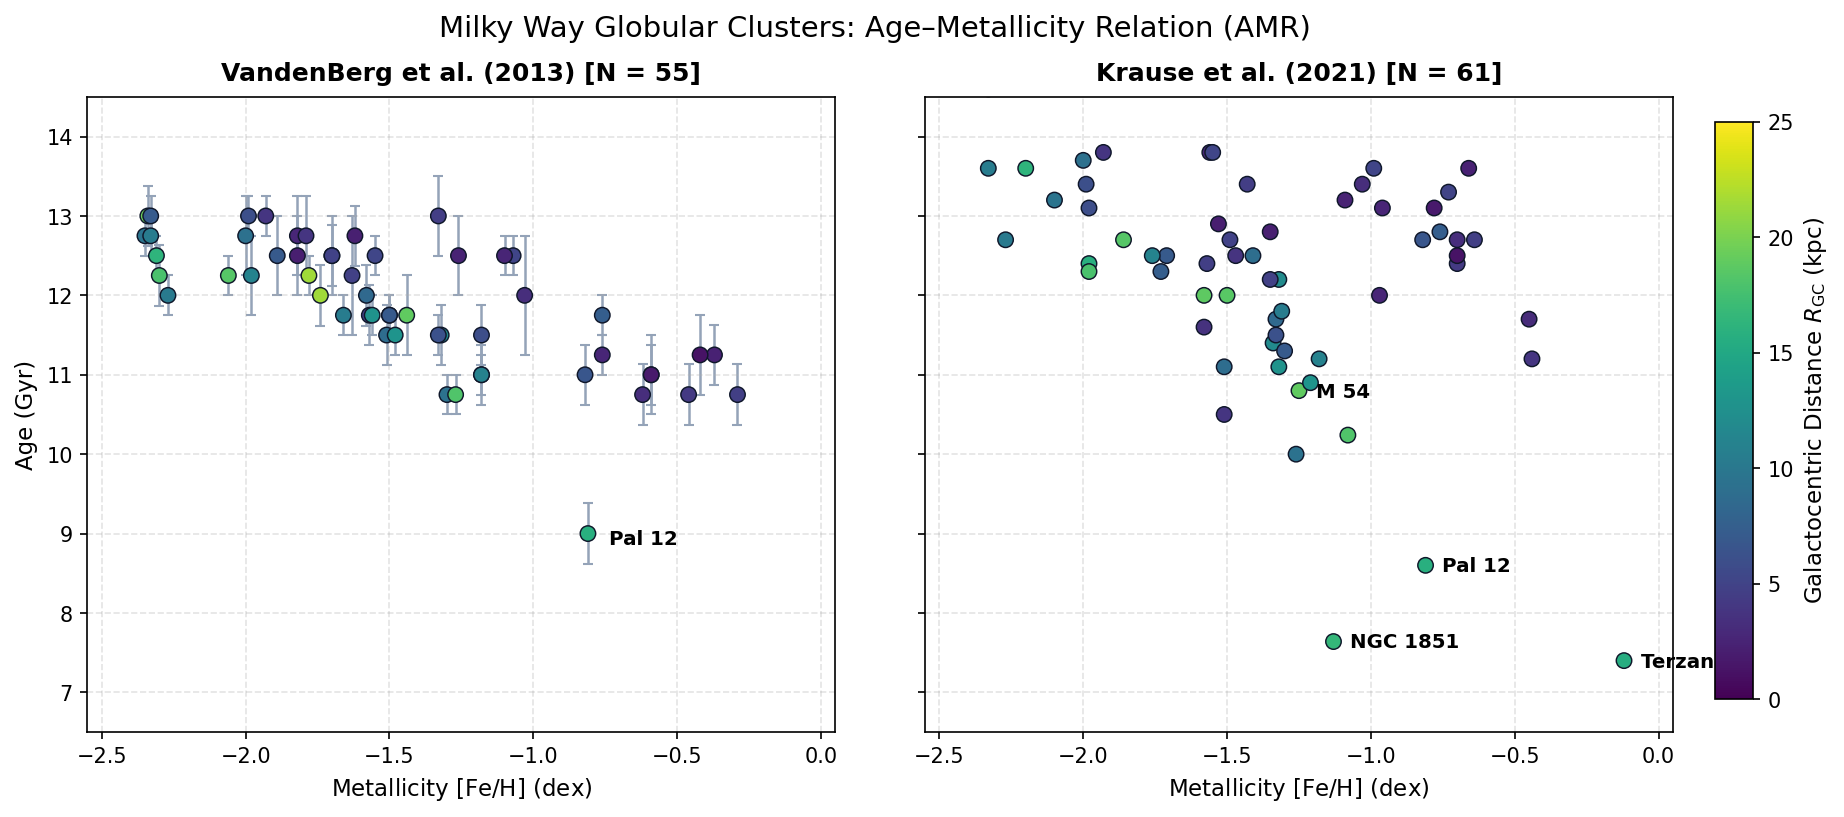

In [14]:
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd
import numpy as np
if 'master' not in globals():
    data_dir = Path('data') if Path('data').exists() else Path('../Data_Raw')
    master = pd.read_csv(data_dir / 'master_catalogue.csv', header=[0, 1], index_col=0)
# Samples
vb_mask = master[('vb', 'Age')].notna() & master[('vb', 'FeH')].notna()
df_vb = master.loc[vb_mask].copy()
k_mask = master[('k', 'Age')].notna() & master[('k', 'FeH')].notna()
df_k = master.loc[k_mask].copy()
names_k = df_k[('meta', 'preferred_name')].fillna(df_k.index.to_series())
names_vb = df_vb[('meta', 'preferred_name')].fillna(df_vb.index.to_series())
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), dpi=150, sharey=True)
# Panel 1: VandenBerg (2013)
ax1.errorbar(
    df_vb[('vb', 'FeH')].astype(float), df_vb[('vb', 'Age')].astype(float),
    yerr=df_vb[('vb', 'Age_err')].astype(float),
    fmt='none', ecolor='#94a3b8', elinewidth=1.2, capsize=2.5, zorder=1
)
sc1 = ax1.scatter(
    df_vb[('vb', 'FeH')].astype(float), df_vb[('vb', 'Age')].astype(float),
    c=df_vb[('vb', 'R_G')].fillna(df_vb[('h1', 'R_gc')]).astype(float),
    cmap='viridis', s=55, edgecolors='#0f172a', linewidths=0.7, zorder=2, vmin=0, vmax=25
)
ax1.set_title(f'VandenBerg et al. (2013) [N = {len(df_vb)}]', fontsize=12, fontweight='bold', pad=8)
ax1.set_xlabel(r'Metallicity $\mathrm{[Fe/H]}$ (dex)', fontsize=11)
ax1.set_ylabel(r'Age (Gyr)', fontsize=11)
ax1.set_xlim(-2.55, 0.05)
ax1.set_ylim(6.5, 14.5)
ax1.grid(True, linestyle='--', alpha=0.35)
p12 = df_vb[names_vb == 'Pal 12']
if not p12.empty:
    ax1.annotate('Pal 12', (float(p12[('vb', 'FeH')].iloc[0]), float(p12[('vb', 'Age')].iloc[0])),
                 xytext=(10, -5), textcoords='offset points', fontsize=9.5, fontweight='bold')
# Panel 2: Krause et al. (2021)
sc2 = ax2.scatter(
    df_k[('k', 'FeH')].astype(float), df_k[('k', 'Age')].astype(float),
    c=df_k[('h1', 'R_gc')].astype(float),
    cmap='viridis', s=55, edgecolors='#0f172a', linewidths=0.7, zorder=2, vmin=0, vmax=25
)
ax2.set_title(f'Krause et al. (2021) [N = {len(df_k)}]', fontsize=12, fontweight='bold', pad=8)
ax2.set_xlabel(r'Metallicity $\mathrm{[Fe/H]}$ (dex)', fontsize=11)
ax2.set_xlim(-2.55, 0.05)
ax2.grid(True, linestyle='--', alpha=0.35)
for name in ['Terzan 7', 'Pal 12', 'NGC 1851', 'M 54']:
    m = df_k[names_k == name]
    if not m.empty:
        ax2.annotate(name, (float(m[('k', 'FeH')].iloc[0]), float(m[('k', 'Age')].iloc[0])),
                     xytext=(8, -3), textcoords='offset points', fontsize=9.5, fontweight='bold')
# shared colorbar
fig.subplots_adjust(right=0.88, wspace=0.12)
cbar_ax = fig.add_axes([0.90, 0.15, 0.018, 0.7])
cbar = fig.colorbar(sc2, cax=cbar_ax)
cbar.set_label(r'Galactocentric Distance $R_{\mathrm{GC}}$ (kpc)', fontsize=11)
fig.suptitle('Milky Way Globular Clusters: Age–Metallicity Relation (AMR)', fontsize=14, y=0.98)
plt.show()


## Candidate Classification

## Extension

## Video Stuff